# Banking77: validation-selected TF-IDF (Term Frequency-Inverse Document Frequency) MLP versus RoBERTa-base LoRA

Run all cells in order using the local CUDA Python kernel. The target is approximately
ten minutes on an RTX 2070 Super (8 GiB); initial package installation and downloads
are outside that budget. Full-run elapsed time is printed at the end.

Both models use the same seeded stratified 85/15 split of the supplied training file.
TF-IDF vocabulary is fitted only on the training partition. Validation macro F1 selects
MLP settings/epoch and the RoBERTa checkpoint; the supplied test file is never used for
training or checkpoint selection. Test metrics and a paired bootstrap interval compare
the selected models, without assuming that RoBERTa must win.

Missing-class precision/recall/F1 is defined as zero and missing predictions are explicitly 
reported, rather than hiding warnings. The new classification head is explicitly initialized 
and the pretrained encoder loaded strictly.

• Term Frequency (TF): Measures how often a specific word appears inside a single document, showing how relevant that word is to that document's content.

• Inverse Document Frequency (IDF): Measures how rare or common a word is across an entire collection of documents (a corpus), reducing the weight of everyday words like "the" or "and".

• TF-IDF Score: The product of Term Frequency and Inverse Document Frequency; it highlights words that are frequent in a specific document but rare across the broader collection.

This version implements a local PII boundary for training, visualization and inference,
and adds privacy tests plus a protected-text word cloud. See the lifecycle and parameter
decision tables below for implementation details, selection criteria and production gaps.


## 1. Privacy boundary and data-management lifecycle

This is a **production-oriented teaching implementation on public Banking77**, not
permission to process live banking records or proof of GDPR/UK GDPR, GLBA or PCI DSS
compliance. The approved exercise scope is English with US/UK identifiers and
international IBAN patterns. Detection can miss PII and can over-redact intent cues.

**Data flow:** approved source CSV -> local normalization -> local PER/LOC NER plus
structured financial/contact/ID recognizers -> irreversible typed placeholders ->
protected-only previews/plots -> decontamination -> shared split -> training-only
TF-IDF fit -> validation selection -> once-per-model test evaluation -> protected
inference and aggregate audit manifest. Both models learn from the same protection.

- No raw text is passed to a remote API, model trainer, word cloud, datasets cache,
  notebook display or output artifact by the implemented path. NER weights are pinned
  and must be cached during setup; detection runs locally without model-hub requests.
- Mask names/locations, standard street addresses, email/URLs, phone patterns, PAN
  candidates, accounts/routing/passport-like values in context, supported IBAN lengths,
  US SSNs, UK NINOs/sort codes/postcodes, contextual US ZIP, DOB, credentials and
  currency-prefixed amounts. Bad checksums do **not** exempt identifiers from masking.
- Typed placeholders retain useful cues (`<CARD>`, `<PERSON>`, `<AMOUNT>`) without a
  reversible mapping. Normalization removes common zero-width obfuscation. Overlapping
  matches are merged so one recognizer does not expose part of another match.
- The NER model is news-domain, not a comprehensive address parser. Its PER/LOC labels
  complement street/postcode patterns; organizations are retained for intent utility.
  Rare formats, lowercase/ambiguous names, unsupported languages, obfuscated contacts,
  unrecognized IDs, and financial facts expressed without matched patterns can escape.
  Masking is **not guaranteed anonymization**; residual text and weights remain sensitive.
- Detection errors, malformed schemas, unknown labels, invalid spans and oversized
  queries stop processing; there is no silent unprotected fallback or tail truncation.
  Synthetic positive/negative and long-query checks must pass before any preview.
- The helper holds raw strings only temporarily, but Python cannot promise secure
  erasure of immutable strings/RAM. Original CSV files are unchanged. Use approved,
  restricted storage and a fresh restricted kernel; do not paste real PII into source.

### Controls that belong outside this notebook

| Control | Teaching implementation | Production release prerequisite |
|---|---|---|
| Purpose/minimization | Protect inputs before training; discard raw fields from downstream objects | Approved lawful basis, consent/notice where applicable, data inventory and DPIA/risk review |
| Access/secrets | No credentials or reversible mapping in source/artifacts | Least-privilege RBAC, MFA, scoped service identities, managed secrets and audited access |
| Encryption/egress | Local NER; public weight cache only | KMS-managed encryption at rest, TLS/encrypted notebook transport, network allowlists and key rotation |
| Retention/deletion | No protected-corpus export; aggregate manifest; separate run directory | Enforced expiry for source, RAM/swap/crash dumps, temporary caches, outputs, weights and backups; deletion/unlearning procedure |
| Quality/audit | Synthetic removal tests, collision counts, pinned detector revision and package versions | Authorized annotated real-domain holdout, entity-level recall/precision by subgroup, red-team tests, signed change/release approval |
| Monitoring/release | Fail-closed gate and redacted inference output | Aggregate-only monitored logs, incident response, drift checks, residual-PII artifact review and human escalation |

Choose entity-specific false-negative tolerances with privacy/compliance teams before
release; a threshold cannot be justified by intent accuracy or 13 synthetic checks.
Do not store PINs/CVV/passwords for this task, even in a purportedly redacted raw log.
Record retention or deletion obligations with the relevant institution; no universal
regulatory retention period or legal conclusion is implied here.


## 2. How to choose parameters and compare models

Separate **privacy policy**, **engineering settings**, and **learned-model selection**.
Do not choose privacy coverage or hyperparameters because they improve the test score.
Choose policy from data inventory/risk, engineering settings from measured hardware
cost and input-length coverage, and trained checkpoints from validation macro F1.

| Portion / setting | Choice and criterion | Evidence to inspect / next experiment |
|---|---|---|
| Detector | Pinned Apache-2.0 DistilBERT PER/LOC plus deterministic rules | English name/location capability, licensing and lower compute than a second large model; validate domain-specific missed entities before release |
| PII window / overlap | 256 / 32 tokens; unlike classifier truncation scan **all** windows | Bounded 8-GiB memory, overlapping boundary context; long-tail synthetic check and measured privacy seconds |
| PII batch / length limit | 64 / 10,000 characters | Batch short queries efficiently; reject oversized input rather than silently missing tail PII; benchmark p95 latency and OOM behavior in service |
| Redaction thresholds | All predicted PER/LOC tokens; no additional confidence cutoff | Favor recall; classifier score is not a privacy risk threshold. Measure false positives and missed entities on authorized annotated text |
| Shared data split | Seed 42, stratified 15% validation after protected-text decontamination | Keep rare intents represented and prevent redaction-created leakage; inspect split sizes, class counts and collision counts |
| TF-IDF | Unigrams+bigrams, cap 12,000, float32, sublinear TF, keep stop words | Phrase/negation utility within dense MLP memory budget; cap is an engineering prior, not proven optimum; compare feature caps using validation |
| MLP | 512/256 hidden units; pairs `(lr=.001, dropout=.2)` / `(.002,.3)` | Keep architecture fixed while measuring two speed/generalization tradeoffs; show search table, validation F1 and elapsed time |
| MLP stopping | Up to 24 epochs, patience 4 | Restore best **validation** epoch; stop spending compute on sustained non-improvement |
| Transformer choice | RoBERTa-base + LoRA rank 16, alpha 32, query/value, dropout .05 | Preserve contextual pretrained knowledge, train <1% of parameters; rank/targets are budgeted priors, not searched optima |
| LoRA search / stopping | Learning rates .0003/.0005, up to 10 epochs, patience 2 | LoRA rates differ from full fine-tuning; show both validation curves and choose macro F1, not the final test result |
| Warmup / decay | 80 warmup steps, weight decay .01, linear LR decay | Stabilize new head/adapters then reduce update noise; inspect training/validation loss rather than blindly increasing epochs |
| Transformer batches | 32 train / 64 eval, FP16, workers 0 | Fit 8 GiB, reduce memory/dispatch cost; avoid Windows worker/compile startup overhead; compare measured peak allocation |
| Classifier max length | 64 tokens, dynamic padding to multiples of 8 | Inspect protected **training-only** 50/95/99 percentiles and truncation fraction; increase only if coverage loss justifies compute |
| Word cloud | Protected training partition only; >=5 documents; exclude placeholder labels | Reduce rare-token exposure and avoid test-informed feature design; cutoff is not differential privacy or an anonymity guarantee |
| Model choice | Accuracy + macro/per-intent F1 + CI + runtime/memory/latency | Choose MLP if cost dominates and its errors are acceptable; choose RoBERTa only if contextual gains justify cost and privacy gates pass |

The ten-minute target includes PII detection and all visualizations after setup.
The searches are small and single-seed, not claims of global optimization or equal
pretraining resources. Redaction changes the data distribution: retrain and report
new protected-run results rather than reusing the earlier unprotected scores.


In [1]:
# Load and prepare the banking77 dataset for training and testing

import os
import sys
import json
from importlib.metadata import version
import random

# Public model downloads are a setup step; customer text is never sent to a service.
os.environ["HF_HUB_DISABLE_TELEMETRY"] = "1"
os.environ["HF_HUB_OFFLINE"] = "1" # Pre-cache public weights in setup; no hub calls during the run.
from pathlib import Path
from time import perf_counter
from tempfile import TemporaryDirectory

import numpy as np
from IPython.display import display
import torch
import pandas as pd
from datasets import Dataset

run_started = perf_counter()
SEED = 42 # From Hitchhiker's Guide to the Galaxy the Answer to the Ultimate Question of Life, 
# the Universe, and Everything
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if not torch.cuda.is_available():
    raise RuntimeError("Select the CUDA-enabled Python kernel: this experiment targets cuda:0.")
device = torch.device("cuda:0")
torch.cuda.set_device(device)
torch.cuda.manual_seed_all(SEED)
print(f"Device: {torch.cuda.get_device_name(device)}")
print(f"GPU memory: {torch.cuda.get_device_properties(device).total_memory / 2**30:.1f} GiB")

PROJECT = Path.cwd()
if not (PROJECT / "datasets" / "banking77_train.csv").is_file():
    PROJECT = PROJECT / "Codecademy" / "Transformers" / "Portfolio_project_MLP_RoBERTa_banking"
if not (PROJECT / "datasets" / "banking77_train.csv").is_file():
    raise FileNotFoundError("Run from the project directory or repository root.")
OUTPUT = PROJECT / "optimized_banking77_protected"
OUTPUT.mkdir(exist_ok=True)

# The helper is importable from either supported working directory.
if str(PROJECT) not in sys.path:
    sys.path.insert(0, str(PROJECT))
from pii_protection import (
    LocalNameDetector, PiiProtector, POLICY_VERSION, NER_MODEL, NER_REVISION,
    read_protected_banking_csv, decontaminate_training, synthetic_privacy_checks,
    wordcloud_frequencies,
)
from datasets import disable_caching

# No raw DataFrame is exposed to the notebook. Learned names/locations and structured
# identifiers are redacted before the original previews, EDA and feature engineering.
# Cache disabling avoids persistent datasets-map caches; any temporary data is protected.
disable_caching()
privacy_started = perf_counter()
protector = PiiProtector(LocalNameDetector(device="cuda:0", batch_size=64))
display(synthetic_privacy_checks(protector))
train_df, train_pii_audit = read_protected_banking_csv(
    PROJECT / "datasets" / "banking77_train.csv", protector
)
test_df, test_pii_audit = read_protected_banking_csv(
    PROJECT / "datasets" / "banking77_test.csv", protector
)

# Redaction can collapse distinct queries. Remove conflicting/duplicate training
# queries and training matches to protected test text, without altering test rows.
train_df, collision_audit = decontaminate_training(train_df, test_df)
privacy_seconds = perf_counter() - privacy_started
print(f"PII policy: {POLICY_VERSION}; local detector: {NER_MODEL}@{NER_REVISION}")
print(f"Protection plus synthetic checks: {privacy_seconds:.1f}s")
display(pd.DataFrame([train_pii_audit, test_pii_audit], index=["Train source", "Test source"]).fillna(0).astype(int))
print("Protected-text collision policy:", collision_audit)
torch.manual_seed(SEED) # Detector loading must not change intent-model initialization.

# Display the first few rows of the training and testing DataFrames to understand their structure

print("Training DataFrame:")
print(train_df.head())
print("\nTesting DataFrame:")
print(test_df.head())

train_dataset = Dataset.from_pandas(train_df)
test_dataset = Dataset.from_pandas(test_df)

# Display the first few rows of the training and testing datasets to verify the conversion from DataFrame to Dataset

print("Training DataFrame Info:")
print(train_df.info())
print("\nTesting DataFrame Info:")
print(test_df.info())

print("\nTraining Dataset:")
print(train_dataset)
print("\nTesting Dataset:")
print(test_dataset)

print("\nTraining Dataset Example:")
print(train_dataset[0])
print("\nTesting Dataset Example:")
print(test_dataset[0])

for frame in (train_df, test_df):
    if frame[["text", "category"]].isna().any().any():
        raise ValueError("Missing text or labels.")
    if frame["text"].str.strip().eq("").any():
        raise ValueError("Empty queries.")
if set(train_df["text"]) & set(test_df["text"]):
    raise ValueError("Protected train/test overlap remains after decontamination.")


Device: NVIDIA GeForce RTX 2070 Super
GPU memory: 8.0 GiB


,Synthetic scenario,All expected identifiers removed
0,PERSON,True
1,ADDRESS,True
2,EMAIL,True
3,PHONE,True
4,CARD,True
5,IBAN,True
6,US_SSN,True
7,UK_NINO,True
8,ACCOUNT,True
9,CREDENTIAL,True


PII policy: banking77-en-us-uk-v1; local detector: dslim/distilbert-NER@dfa2838a127384aabb82ed7719e16dab84c42a2a
Protection plus synthetic checks: 24.4s


,LOCATION,AMOUNT,IBAN,PERSON,changed_rows,rows
Train source,315,115,10,27,418,10003
Test source,92,22,0,9,114,3080


Protected-text collision policy: {'train_rows_matching_protected_test': 7, 'ambiguous_protected_train_rows': 0, 'duplicate_protected_train_rows': 6}
Training DataFrame:
                                                text      category
0                     I am still waiting on my card?  card_arrival
1  What can I do if my card still hasn't arrived ...  card_arrival
2  I have been waiting over a week. Is the card s...  card_arrival
3  Can I track my card while it is in the process...  card_arrival
4  How do I know if I will get my card, or if it ...  card_arrival

Testing DataFrame:
                                                text      category
0                           How do I locate my card?  card_arrival
1  I still have not received my new card, I order...  card_arrival
2  I ordered a card but it has not arrived. Help ...  card_arrival
3   Is there a way to know when my card will arrive?  card_arrival
4                       My card has not arrived yet.  card_arrival
Trainin

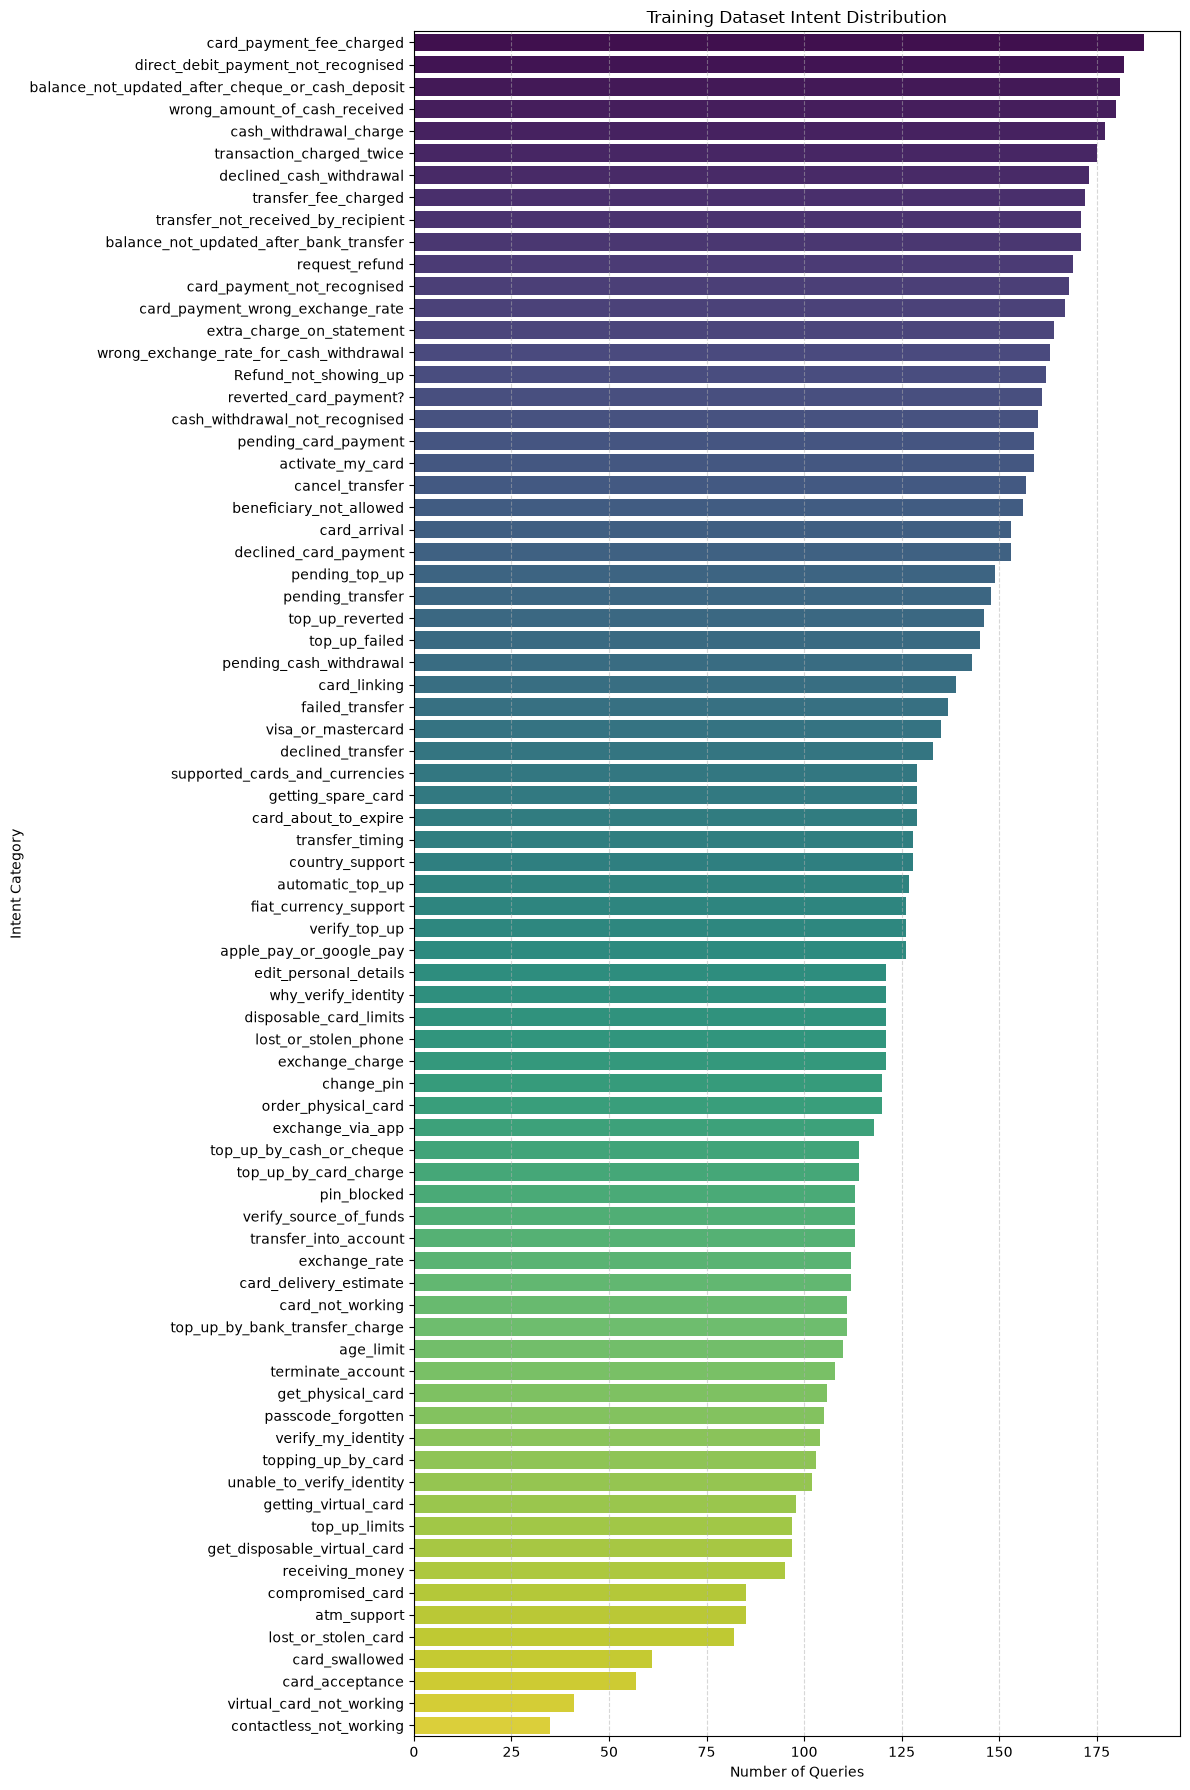

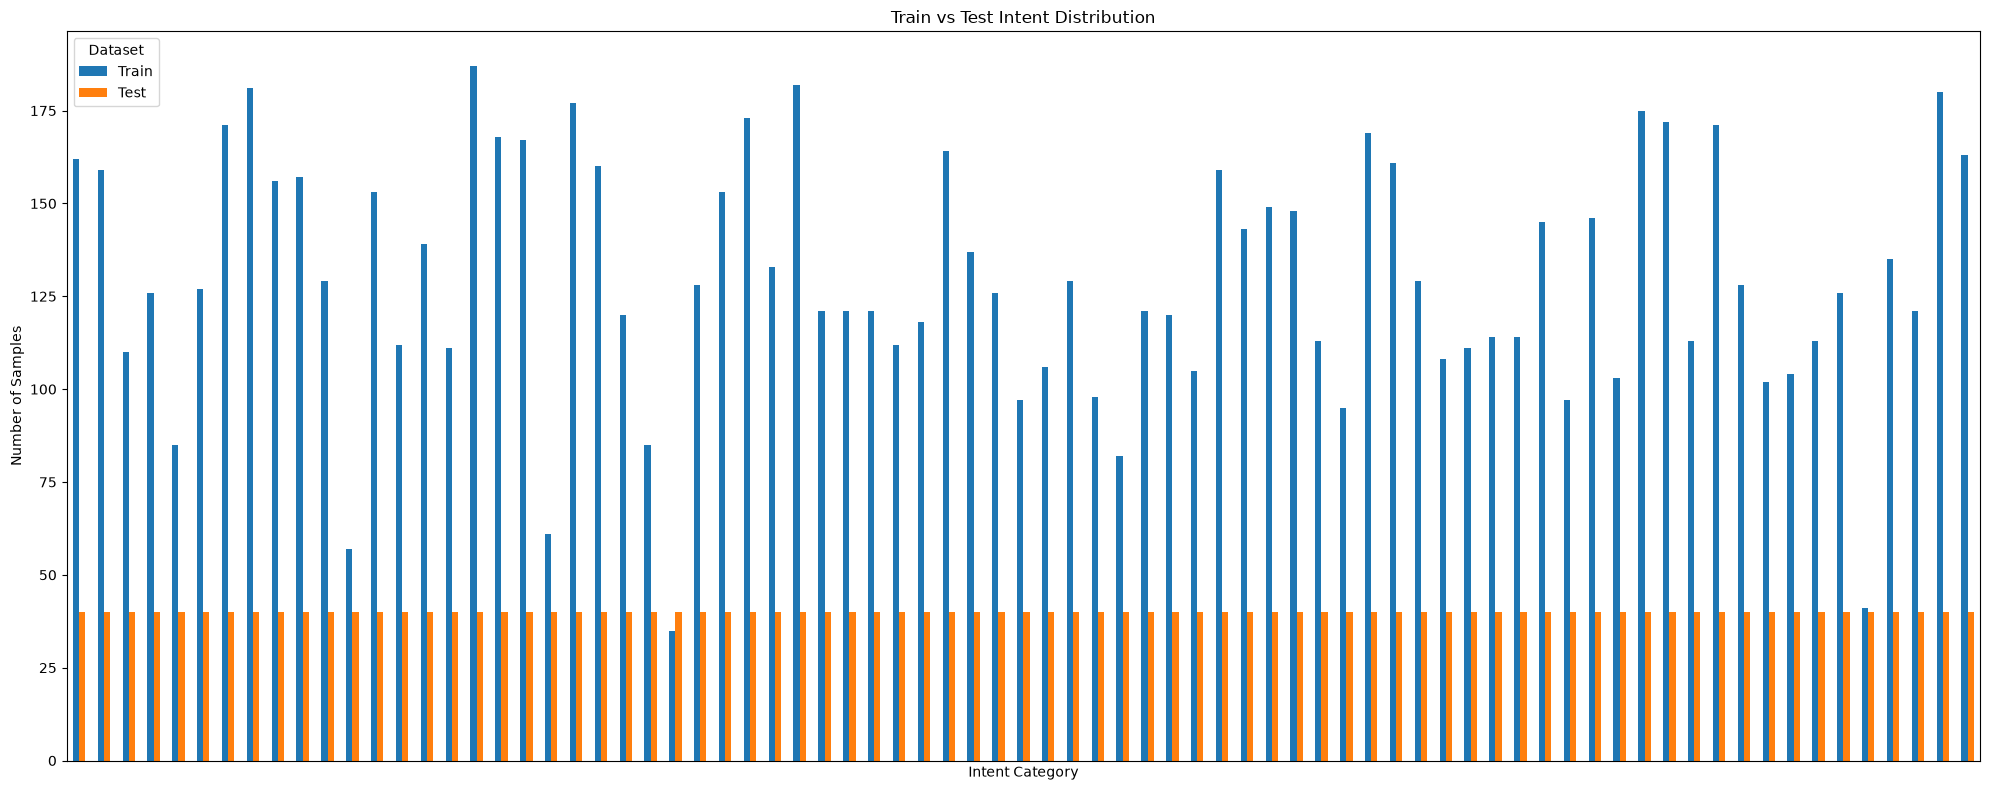

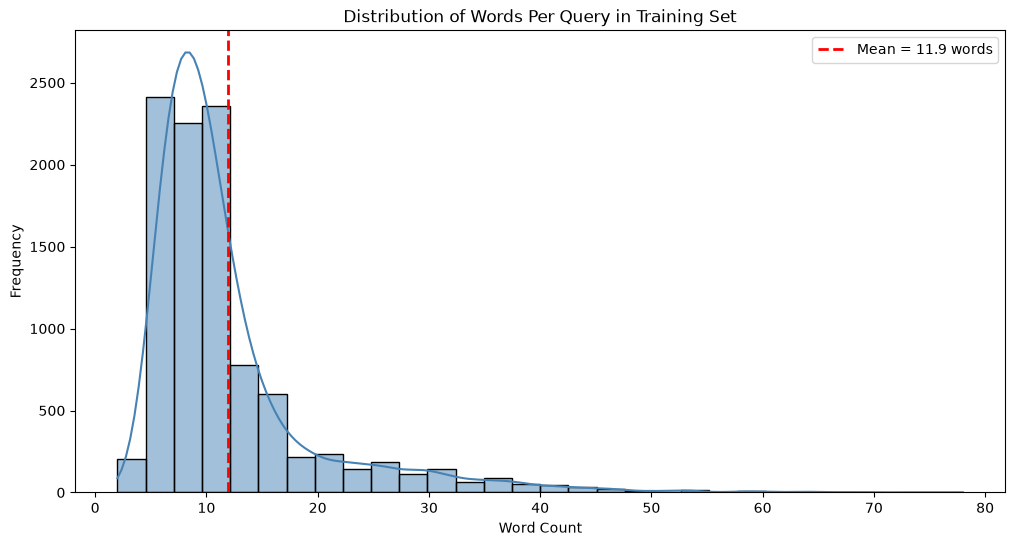

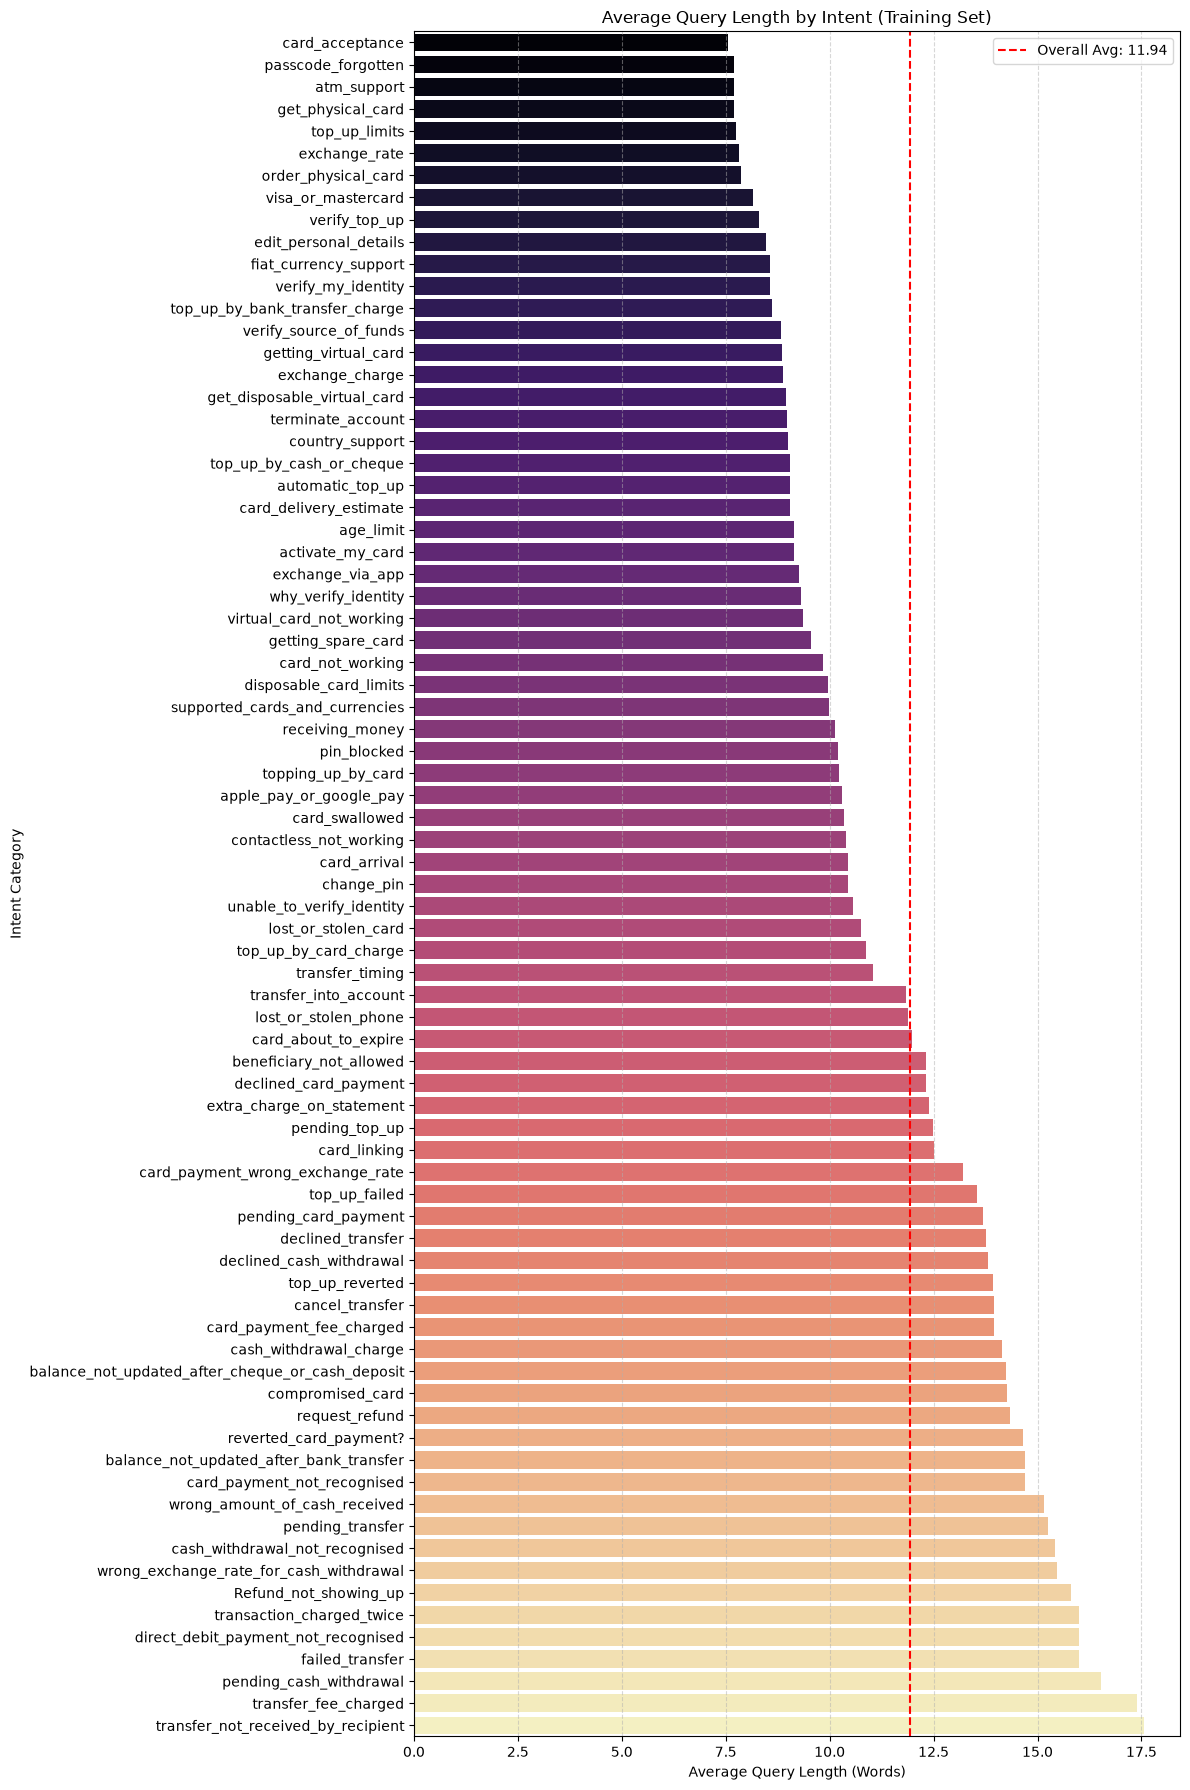

count    9990.000000
mean       11.942743
std         7.867338
min         2.000000
25%         7.000000
50%        10.000000
75%        13.000000
max        78.000000
Name: word_count, dtype: float64

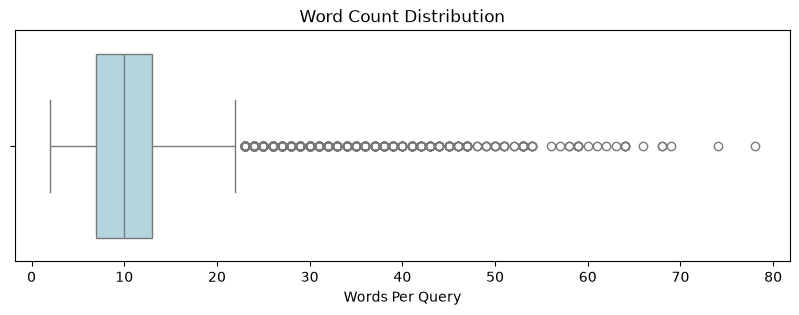

In [2]:
# Data visualizations

import matplotlib.pyplot as plt
import seaborn as sns

# The average query length distribution was examined for both training and testing sets. Because the test set exhibited a nearly identical pattern to the training set, only the training visualization is presented to avoid redundancy.

# Visualize the distribution of intent categories in the training dataset

plot_df = (
    train_df["category"]
    .value_counts()
    .reset_index()
)

plot_df.columns = ["category", "count"]

plt.figure(figsize=(12, 18))

sns.barplot(
    data=plot_df,
    x="count",
    y="category",
    hue="category",
    palette="viridis",
    legend=False
)

plt.title("Training Dataset Intent Distribution")
plt.xlabel("Number of Queries")
plt.ylabel("Intent Category")
plt.grid(axis="x", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

# Compare the distribution of intent categories between the training and testing datasets

train_counts = train_df["category"].value_counts().sort_index()
test_counts = test_df["category"].value_counts().sort_index()

comparison_df = pd.DataFrame({
    "Train": train_counts,
    "Test": test_counts
})

comparison_df.plot(
    kind="bar",
    figsize=(20, 8)
)

plt.title("Train vs Test Intent Distribution")
plt.xlabel("Intent Category")
plt.ylabel("Number of Samples")
plt.xticks([])
plt.legend(title="Dataset")
plt.tight_layout()
plt.show()

# Visualize the distribution of words per query in the training and testing datasets

train_df["word_count"] = train_df["text"].apply(
    lambda x: len(x.split())
)

mean_words = train_df["word_count"].mean()

plt.figure(figsize=(12, 6))

sns.histplot(
    data=train_df,
    x="word_count",
    bins=30,
    kde=True,
    color="steelblue"
)

plt.axvline(
    mean_words,
    color="red",
    linestyle="--",
    linewidth=2,
    label=f"Mean = {mean_words:.1f} words"
)

plt.title("Distribution of Words Per Query in Training Set")
plt.xlabel("Word Count")
plt.ylabel("Frequency")

plt.legend()

plt.show()

# Visualize the average query length by intent category in the training and testing datasets

avg_length = (
    train_df
    .groupby("category")["word_count"]
    .mean()
    .sort_values()
)

avg_length_df = avg_length.reset_index()
avg_length_df.columns = ["category", "avg_word_count"]
overall_avg = train_df["word_count"].mean()

plt.figure(figsize=(12, 18))

sns.barplot(
    data=avg_length_df,
    x="avg_word_count",
    y="category",
    hue="category",
    palette="magma",
    legend=False
)

plt.axvline(
    overall_avg, 
    color="red", 
    linestyle="--", 
    label=f"Overall Avg: {overall_avg:.2f}"
)
plt.legend()

plt.title("Average Query Length by Intent (Training Set)")
plt.xlabel("Average Query Length (Words)")
plt.ylabel("Intent Category")

plt.grid(axis="x", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

# Summary statistics and box plot for word count distribution in the training set

display(train_df["word_count"].describe())

plt.figure(figsize=(10, 3))

sns.boxplot(
    data=train_df,
    x="word_count",
    color="lightblue"
)

plt.title("Word Count Distribution")
plt.xlabel("Words Per Query")

plt.show()

In [3]:
# Preprocessing for MLP Baseline
# 1. Encode intent labels
# 2. Vectorize customer queries using TF-IDF

from sklearn.model_selection import train_test_split
from scipy.sparse import csr_matrix
from sklearn.preprocessing import LabelEncoder
from sklearn.feature_extraction.text import TfidfVectorizer

# -----------------------------
# Encode intent labels
# -----------------------------

label_encoder = LabelEncoder() # Initialize the label encoder for encoding intent labels as integers

fit_df, validation_df = train_test_split(
    train_df, 
    test_size=0.15, # 15% of the training data will be used for validation
    stratify=train_df["category"], # Ensure the split maintains the same distribution of categories as the original training set
    random_state=SEED # Ensure reproducibility of the split
)
# Decontamination above leaves one row per normalized protected training query,
# preventing the same protected input from appearing in training and validation.
fit_df = fit_df.reset_index(drop=True) # Reset the index of the training split
validation_df = validation_df.reset_index(drop=True) # Reset the index of the validation split
y_train = np.asarray(label_encoder.fit_transform(fit_df["category"]), dtype=np.int64) # Encode the training intent labels as integers
y_validation = np.asarray(label_encoder.transform(validation_df["category"]), dtype=np.int64) # Encode the validation intent labels as integers
print(f"Shared split: {len(fit_df)} train / {len(validation_df)} validation / {len(test_df)} test") # Display the number of samples in each split
y_test = np.asarray(label_encoder.transform(test_df["category"]), dtype=np.int64) # Encode the test intent labels as integers

print(f"Number of intent classes: {len(label_encoder.classes_)}")

print("\nSample label mappings:")
for intent, label in zip(
    label_encoder.classes_[:10],
    range(min(10, len(label_encoder.classes_)))
):
    print(f"{label}: {intent}")

# -----------------------------
# Vectorize query text with TF-IDF
# -----------------------------

tfidf_vectorizer = TfidfVectorizer(
    lowercase=True, # Convert all characters to lowercase to ensure uniformity in the feature matrix
    stop_words=None, # Preserve negation and banking phrases; removing stop words loses intent cues.
    ngram_range=(1, 2),
    sublinear_tf=True,
    dtype=np.float32,
    max_features=12000 # For Banking77 (~10k training samples), this is a reasonable starting point:
    # Large enough to capture important vocabulary
    # Small enough to train quickly
    # Appropriate for a baseline model
)

X_train = csr_matrix(tfidf_vectorizer.fit_transform(fit_df["text"]), dtype=np.float32) # Convert the training text data into a sparse TF-IDF feature matrix using csr_matrix
X_validation = csr_matrix(tfidf_vectorizer.transform(validation_df["text"]), dtype=np.float32) # Convert the validation text data into a sparse TF-IDF feature matrix using csr_matrix
X_test = csr_matrix(tfidf_vectorizer.transform(test_df["text"]), dtype=np.float32) # Convert the test text data into a sparse TF-IDF feature matrix using csr_matrix

print("\nTF-IDF Matrix Shapes:")
print(f"Training Features Matrix Shape: {X_train.shape}") # Display the shape of the training features matrix (number of samples x number of features)
print(f"Testing Features Matrix Shape: {X_test.shape}") # Display the shape of the testing features matrix (number of samples x number of features)
print(f"Validation Features Matrix Shape: {X_validation.shape}") # Display the shape of the validation features matrix (number of samples x number of features)

print(f"\nVocabulary Size: {len(tfidf_vectorizer.vocabulary_)}")

print("\nNumber of intent classes:")
print(len(label_encoder.classes_))

print("\nFirst 10 intent classes:")
print(list(label_encoder.classes_[:10]))

Shared split: 8491 train / 1499 validation / 3080 test
Number of intent classes: 77

Sample label mappings:
0: Refund_not_showing_up
1: activate_my_card
2: age_limit
3: apple_pay_or_google_pay
4: atm_support
5: automatic_top_up
6: balance_not_updated_after_bank_transfer
7: balance_not_updated_after_cheque_or_cash_deposit
8: beneficiary_not_allowed
9: cancel_transfer



TF-IDF Matrix Shapes:
Training Features Matrix Shape: (8491, 12000)
Testing Features Matrix Shape: (3080, 12000)
Validation Features Matrix Shape: (1499, 12000)

Vocabulary Size: 12000

Number of intent classes:
77

First 10 intent classes:
['Refund_not_showing_up', 'activate_my_card', 'age_limit', 'apple_pay_or_google_pay', 'atm_support', 'automatic_top_up', 'balance_not_updated_after_bank_transfer', 'balance_not_updated_after_cheque_or_cash_deposit', 'beneficiary_not_allowed', 'cancel_transfer']


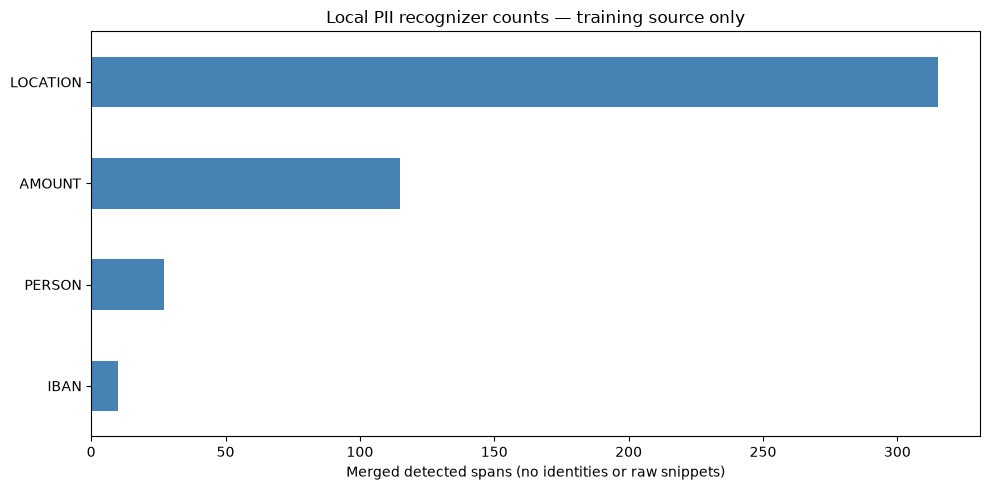

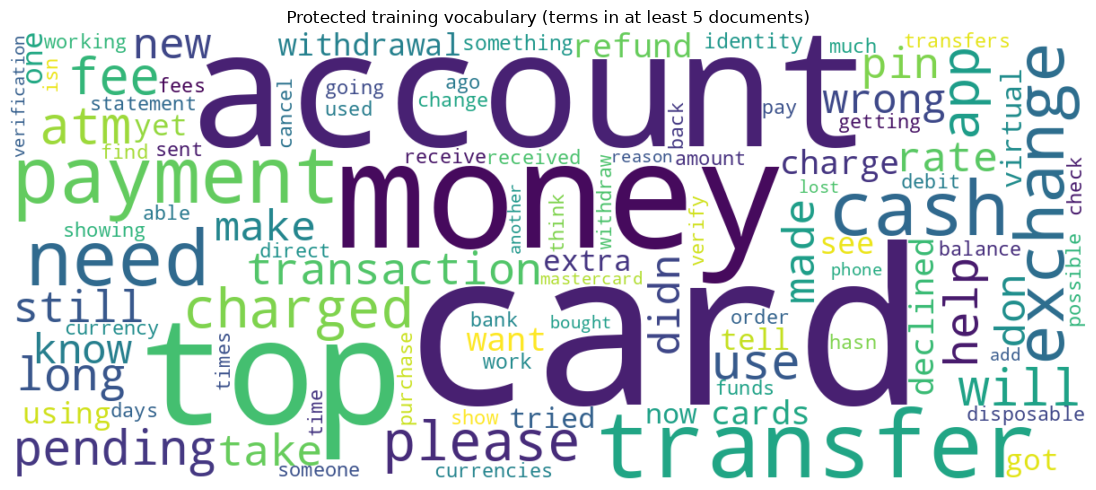

Word-cloud eligibility uses document frequency; no test queries or placeholder labels are included.


In [4]:
# Additive privacy/EDA plots: no original visualization is removed.
from wordcloud import WordCloud, STOPWORDS

# These are recognizer counts, not verified numbers of people or a recall estimate.
privacy_counts = pd.Series({
    key: count for key, count in train_pii_audit.items()
    if key not in {"rows", "changed_rows"}
}, dtype="int64").sort_values()
plt.figure(figsize=(10, 5))
if privacy_counts.empty:
    plt.text(0.5, 0.5, "No training identifiers detected (not proof of no PII)", ha="center")
    plt.xticks([])
    plt.yticks([])
else:
    privacy_counts.plot.barh(color="steelblue")
plt.title("Local PII recognizer counts — training source only")
plt.xlabel("Merged detected spans (no identities or raw snippets)")
plt.tight_layout()
plt.show()

# Fit the visualization on training-only protected text. A rare or missed identifier
# can still escape detection; the document-frequency floor is not a release guarantee.
safe_frequencies = wordcloud_frequencies(fit_df["text"].tolist(), minimum_documents=5)
safe_frequencies = {term: count for term, count in safe_frequencies.items() if term not in STOPWORDS}
plt.figure(figsize=(12, 5))
if safe_frequencies:
    cloud = WordCloud(
        width=1200, height=500, max_words=100, background_color="white",
        random_state=SEED, collocations=False
    ).generate_from_frequencies(safe_frequencies)
    plt.imshow(cloud, interpolation="bilinear")
else:
    plt.text(0.5, 0.5, "No protected training terms meet the document-frequency policy", ha="center")
plt.axis("off")
plt.title("Protected training vocabulary (terms in at least 5 documents)")
plt.tight_layout()
plt.show()
print("Word-cloud eligibility uses document frequency; no test queries or placeholder labels are included.")


In [5]:
# MLP Baseline: Training and Evaluation

# torch already imported in cell 1
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import accuracy_score, classification_report

# --------------------------------------------------
# Convert TF-IDF matrices to PyTorch tensors
# --------------------------------------------------

# TF-IDF produces sparse matrices, but MLPs require dense tensors.

X_train_tensor = torch.tensor(
    X_train.toarray(),
    dtype=torch.float32
)

X_validation_tensor = torch.from_numpy(X_validation.toarray()).to(device)
y_validation_tensor = torch.from_numpy(y_validation).to(device)

X_test_tensor = torch.tensor(
    X_test.toarray(),
    dtype=torch.float32
)

y_train_tensor = torch.tensor(
    y_train,
    dtype=torch.long
)

y_test_tensor = torch.tensor(
    y_test,
    dtype=torch.long
)

# --------------------------------------------------
# Create DataLoaders
# --------------------------------------------------

# Batch size of 256 amortizes GPU dispatch overhead for the small MLP:
# - Large enough for efficient training
# - Small enough to fit comfortably in memory

batch_size = 256

train_dataset = TensorDataset(
    X_train_tensor,
    y_train_tensor
)

test_dataset = TensorDataset(
    X_test_tensor,
    y_test_tensor
)

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False
)

# --------------------------------------------------
# Build MLP Architecture
# --------------------------------------------------

class BankingMLP(nn.Module):

    def __init__(self, input_dim: int, num_classes: int, dropout: float = 0.2):
        super().__init__()

        self.network = nn.Sequential(

            nn.Linear(input_dim, 512), # First hidden layer
            nn.ReLU(), # ReLU introduces non-linearity, allowing the model to learn more complex patterns.
            nn.Dropout(dropout), # Dropout helps reduce overfitting; its rate is selected using validation.
            nn.Linear(512, 256), # Second hidden layer
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(256, num_classes) # Output layer
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.network(x)

input_dim = X_train_tensor.shape[1] # Input dimension equals TF-IDF vocabulary size

num_classes = len(label_encoder.classes_) # Banking77 contains 77 intent classes

mlp_model = BankingMLP(
    input_dim=input_dim,
    num_classes=num_classes
).to(device)

print(mlp_model)

# --------------------------------------------------
# Loss Function and Optimizer
# --------------------------------------------------

# CrossEntropyLoss is the standard choice for multi-class classification.

criterion = nn.CrossEntropyLoss()

# AdamW is commonly used because:
# - Adaptive learning rates
# - Weight decay for improved generalization

optimizer = torch.optim.AdamW(
    mlp_model.parameters(),
    lr=0.001,
    weight_decay=0.01
)

# --------------------------------------------------
# Training Loop
# --------------------------------------------------

epochs = 24
torch.cuda.reset_peak_memory_stats()
mlp_started = perf_counter()
mlp_search: list[dict[str, float]] = []
best_mlp_f1 = -1.0
best_mlp_state: dict[str, torch.Tensor] = {}
X_fit_gpu = X_train_tensor.to(device)
y_fit_gpu = y_train_tensor.to(device)

for learning_rate, dropout in ((0.001, 0.2), (0.002, 0.3)):
    torch.manual_seed(SEED)
    candidate = BankingMLP(input_dim, num_classes, dropout).to(device)
    optimizer = torch.optim.AdamW(candidate.parameters(), lr=learning_rate, weight_decay=0.01)
    candidate_best = -1.0
    stale_epochs = 0
    for epoch in range(epochs):
        candidate.train()
        running_loss = 0.0
        correct_predictions = 0
        total_predictions = 0
        order = torch.randperm(len(y_fit_gpu), device=device)
        for indices in order.split(batch_size):
            batch_x, batch_y = X_fit_gpu[indices], y_fit_gpu[indices]
            optimizer.zero_grad() # Clear previous gradients
            outputs = candidate(batch_x) # Forward pass through the network
            loss = criterion( # Compute the loss between predictions and true labels
                outputs, batch_y
            )
            # Backpropagation and optimization steps follow
            loss.backward()
            optimizer.step()
            running_loss += float(loss.detach()) * len(indices)
            correct_predictions += int((outputs.argmax(dim=1) == batch_y).sum())
            total_predictions += len(indices)
        candidate.eval()
        with torch.inference_mode():
            validation_predictions = candidate(X_validation_tensor).argmax(dim=1).cpu().numpy()
        from sklearn.metrics import f1_score
        validation_f1 = float(f1_score(y_validation, validation_predictions, average="macro", zero_division=0))
        print(
            f"MLP lr={learning_rate}, dropout={dropout} | Epoch {epoch + 1}/{epochs} | "
            f"Loss: {running_loss / total_predictions:.4f} | "
            f"Accuracy: {correct_predictions / total_predictions:.4f} | Validation macro F1: {validation_f1:.4f}"
        )
        if validation_f1 > best_mlp_f1:
            best_mlp_f1 = validation_f1
            best_mlp_state = {name: value.detach().cpu().clone() for name, value in candidate.state_dict().items()}
        if validation_f1 > candidate_best:
            candidate_best = validation_f1
            stale_epochs = 0
        else:
            stale_epochs += 1
        if stale_epochs >= 4:
            break
    mlp_search.append({"learning_rate": learning_rate, "dropout": dropout, "validation_macro_f1": candidate_best})
mlp_model.load_state_dict(best_mlp_state, strict=True)
torch.cuda.synchronize()
mlp_training_seconds = perf_counter() - mlp_started
mlp_peak_gib = torch.cuda.max_memory_allocated() / 2**30
del X_fit_gpu, y_fit_gpu, candidate, optimizer
display(pd.DataFrame(mlp_search))
print(f"MLP search + selection: {mlp_training_seconds:.1f}s; best validation macro F1: {best_mlp_f1:.4f}")

# --------------------------------------------------
# Evaluation
# --------------------------------------------------

mlp_model.eval()
torch.cuda.synchronize()
mlp_prediction_started = perf_counter()

all_predictions: list[int] = []
all_targets: list[int] = []

with torch.no_grad():

    for batch_x, batch_y in test_loader:

        batch_x = batch_x.to(device)

        outputs = mlp_model(batch_x)

        predictions = torch.argmax(
            outputs,
            dim=1
        )

        all_predictions.extend(
            predictions.cpu().tolist()
        )

        all_targets.extend(
            batch_y.tolist()
        )

# --------------------------------------------------
# Metrics
# --------------------------------------------------
torch.cuda.synchronize()
mlp_prediction_seconds = perf_counter() - mlp_prediction_started

test_accuracy = accuracy_score(
    all_targets,
    all_predictions
)

print("\nTest Accuracy:")
print(f"{test_accuracy:.4f}")

print("\nClassification Report:")
print(
    classification_report(
        all_targets,
        all_predictions,
        target_names=label_encoder.classes_.tolist(),
        labels=list(range(num_classes)),
        zero_division=0
    )
)
torch.save({"state_dict": best_mlp_state, "input_dim": input_dim, "num_classes": num_classes}, OUTPUT / "mlp.pt")
import joblib
joblib.dump({"vectorizer": tfidf_vectorizer, "labels": label_encoder}, OUTPUT / "mlp_preprocessing.joblib")


BankingMLP(
  (network): Sequential(
    (0): Linear(in_features=12000, out_features=512, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.2, inplace=False)
    (3): Linear(in_features=512, out_features=256, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.2, inplace=False)
    (6): Linear(in_features=256, out_features=77, bias=True)
  )
)


MLP lr=0.001, dropout=0.2 | Epoch 1/24 | Loss: 4.2766 | Accuracy: 0.0634 | Validation macro F1: 0.0425
MLP lr=0.001, dropout=0.2 | Epoch 2/24 | Loss: 3.4991 | Accuracy: 0.3037 | Validation macro F1: 0.4404


MLP lr=0.001, dropout=0.2 | Epoch 3/24 | Loss: 1.7663 | Accuracy: 0.6705 | Validation macro F1: 0.7293
MLP lr=0.001, dropout=0.2 | Epoch 4/24 | Loss: 0.7143 | Accuracy: 0.8596 | Validation macro F1: 0.8119


MLP lr=0.001, dropout=0.2 | Epoch 5/24 | Loss: 0.3670 | Accuracy: 0.9282 | Validation macro F1: 0.8524
MLP lr=0.001, dropout=0.2 | Epoch 6/24 | Loss: 0.2167 | Accuracy: 0.9615 | Validation macro F1: 0.8583


MLP lr=0.001, dropout=0.2 | Epoch 7/24 | Loss: 0.1464 | Accuracy: 0.9759 | Validation macro F1: 0.8513
MLP lr=0.001, dropout=0.2 | Epoch 8/24 | Loss: 0.0994 | Accuracy: 0.9854 | Validation macro F1: 0.8668


...

MLP lr=0.002, dropout=0.3 | Epoch 9/24 | Loss: 0.0364 | Accuracy: 0.9925 | Validation macro F1: 0.8620
MLP lr=0.002, dropout=0.3 | Epoch 10/24 | Loss: 0.0296 | Accuracy: 0.9940 | Validation macro F1: 0.8673


,learning_rate,dropout,validation_macro_f1
0,0.001,0.2,0.867333
1,0.002,0.3,0.868988


MLP search + selection: 4.1s; best validation macro F1: 0.8690



Test Accuracy:
0.8786

Classification Report:
                                                  precision    recall  f1-score   support

                           Refund_not_showing_up       0.93      0.93      0.93        40
                                activate_my_card       0.95      0.95      0.95        40
                                       age_limit       0.95      1.00      0.98        40
                         apple_pay_or_google_pay       1.00      1.00      1.00        40
                                     atm_support       0.83      0.95      0.88        40
                                automatic_top_up       1.00      0.90      0.95        40
         balance_not_updated_after_bank_transfer       0.71      0.80      0.75        40
balance_not_updated_after_cheque_or_cash_deposit       0.97      0.93      0.95        40
                         beneficiary_not_allowed       0.86      0.93      0.89        40
                                 cancel_transfer    

['C:\\Users\\nomadant\\AI_Engineering_Lessons\\Codecademy\\Transformers\\engineer-neural-networks-portfolio-project\\optimized_banking77_protected\\mlp_preprocessing.joblib']

In [6]:
# RoBERTa Preprocessing
# 1. Encode labels
# 2. Tokenize query text
# 3. Prepare datasets for LoRA fine-tuning

from transformers import AutoTokenizer
from transformers import DataCollatorWithPadding

# --------------------------------------------------
# Encode Intent Labels
# --------------------------------------------------

# Reuse the shared encoder so both pipelines use exactly the same label mapping.
roberta_fit = fit_df[["text"]].copy()
roberta_validation = validation_df[["text"]].copy()
roberta_test = test_df[["text"]].copy()
roberta_fit["label"] = y_train.tolist()
roberta_validation["label"] = y_validation.tolist()
roberta_test["label"] = y_test.tolist()

print("Number of Intent Classes:")
print(len(label_encoder.classes_))

print("\nSample Label Mappings:")

for idx, intent in enumerate(label_encoder.classes_[:10]):
    print(f"{idx}: {intent}")

# --------------------------------------------------
# Load RoBERTa Tokenizer
# --------------------------------------------------

# roberta-base is chosen because:
#
# - Widely used baseline transformer
# - Relatively lightweight
# - Excellent NLP performance
# - Pretrained on a large English corpus
#
# Larger variants exist:
# - roberta-large
#
# but they require significantly more memory.

model_name = "roberta-base"
ROBERTA_REVISION = "e2da8e2f811d1448a5b465c236feacd80ffbac7b"

tokenizer = AutoTokenizer.from_pretrained(
    model_name, revision=ROBERTA_REVISION, local_files_only=True
)

# --------------------------------------------------
# Tokenization Function
# --------------------------------------------------

def tokenize_function(examples):

    return tokenizer(
        examples["text"],
        truncation=True, # Queries longer than max_length will be truncated.
        max_length=64, # Banking77 queries are generally short. 
        # 64 tokens is typically more than enough.
        # Benefits:
        # - Faster training
        # - Lower memory usage
        # - Minimal information loss
        padding=False # The collator pads only to the longest sequence within each batch.
    )

# --------------------------------------------------
# Convert DataFrames to Hugging Face Datasets
# --------------------------------------------------

train_dataset_roberta = Dataset.from_pandas(roberta_fit, preserve_index=False)
test_dataset_roberta = Dataset.from_pandas(roberta_test, preserve_index=False)
validation_dataset_roberta = Dataset.from_pandas(roberta_validation, preserve_index=False)

# --------------------------------------------------
# Apply Tokenization
# --------------------------------------------------

train_dataset_roberta = train_dataset_roberta.map(tokenize_function, batched=True, remove_columns=["text"])
test_dataset_roberta = test_dataset_roberta.map(tokenize_function, batched=True, remove_columns=["text"])

# --------------------------------------------------
# Verify Results
# --------------------------------------------------

print("\nTraining Dataset:")

print(train_dataset_roberta)

print("\nTesting Dataset:")

print(test_dataset_roberta)

print("\nExample Tokenized Query:")

print(train_dataset_roberta[0])

print("\nDecoded Example:")

print(
    tokenizer.decode(
        train_dataset_roberta[0]["input_ids"]
    )
)

validation_dataset_roberta = validation_dataset_roberta.map(
    tokenize_function, batched=True, remove_columns=["text"]
)
data_collator = DataCollatorWithPadding(tokenizer=tokenizer, pad_to_multiple_of=8)
token_lengths = np.asarray([len(ids) for ids in tokenizer(fit_df["text"].tolist(), truncation=False)["input_ids"]])
print(f"Training-only token lengths (50/95/99 percentile): {np.percentile(token_lengths, [50, 95, 99])}")
print(f"Training queries truncated at 64 tokens: {(token_lengths > 64).mean():.2%}")
print("Validation Dataset:", validation_dataset_roberta)


Number of Intent Classes:
77

Sample Label Mappings:
0: Refund_not_showing_up
1: activate_my_card
2: age_limit
3: apple_pay_or_google_pay
4: atm_support
5: automatic_top_up
6: balance_not_updated_after_bank_transfer
7: balance_not_updated_after_cheque_or_cash_deposit
8: beneficiary_not_allowed
9: cancel_transfer


Map:   0%|          | 0/8491 [00:00<?, ? examples/s]

Map:   0%|          | 0/3080 [00:00<?, ? examples/s]


Training Dataset:
Dataset({
    features: ['label', 'input_ids', 'attention_mask'],
    num_rows: 8491
})

Testing Dataset:
Dataset({
    features: ['label', 'input_ids', 'attention_mask'],
    num_rows: 3080
})

Example Tokenized Query:
{'label': 53, 'input_ids': [0, 6179, 109, 38, 4190, 10, 3207, 14, 21, 41411, 2], 'attention_mask': [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]}

Decoded Example:
<s>How do I fix a payment that was reverted</s>


Map:   0%|          | 0/1499 [00:00<?, ? examples/s]

Training-only token lengths (50/95/99 percentile): [13.  36.  51.1]
Training queries truncated at 64 tokens: 0.29%
Validation Dataset: Dataset({
    features: ['label', 'input_ids', 'attention_mask'],
    num_rows: 1499
})


In [7]:
# RoBERTa + LoRA Configuration and Fine-Tuning

from importlib.util import find_spec
from copy import deepcopy
import logging
import numpy as np

# PyTorch on Windows logs a capability notice for optional Triton FLOP counting.
# This notebook uses eager AdamW and does not request FLOP accounting or Triton kernels.
class OptionalTritonNotice(logging.Filter):
    def filter(self, record: logging.LogRecord) -> bool:
        return record.getMessage() != "triton not found; flop counting will not work for triton kernels"

triton_notice = OptionalTritonNotice()
flop_logger = logging.getLogger("torch.utils.flop_counter")
flop_logger.addFilter(triton_notice)
if find_spec("triton") is None:
    print("Optional Triton FLOP accounting unavailable on this Windows runtime; not used by this experiment.")

from transformers import (
    RobertaConfig,
    RobertaForSequenceClassification,
    EvalPrediction,
    EarlyStoppingCallback,
    TrainingArguments,
    Trainer
)
flop_logger.removeFilter(triton_notice)
from huggingface_hub import hf_hub_download
from safetensors.torch import load_file

from peft import (
    LoraConfig,
    PeftConfig,
    TaskType,
    get_peft_model
)

from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support
)

# --------------------------------------------------
# Evaluation Metrics
# --------------------------------------------------

def compute_metrics(eval_pred: EvalPrediction) -> dict[str, float]:

    logits = eval_pred.predictions
    if isinstance(logits, tuple):
        logits = logits[0]
    labels = eval_pred.label_ids
    if labels is None:
        raise ValueError("Evaluation requires true labels.")

    predictions = np.argmax(
        logits,
        axis=1
    )

    accuracy = accuracy_score(
        labels,
        predictions
    )

    precision, recall, f1, _ = (
        precision_recall_fscore_support(
            labels,
            predictions,
            average="weighted",
            zero_division=0
        )
    )

    return {
        "macro_f1": float(f1_score(labels, predictions, average="macro", zero_division=0)),
        "accuracy": float(accuracy),
        "precision": float(precision),
        "recall": float(recall),
        "f1": float(f1)
    }

# --------------------------------------------------
# Load Pretrained RoBERTa
# --------------------------------------------------

torch.manual_seed(SEED)
config = RobertaConfig.from_pretrained(model_name, revision=ROBERTA_REVISION, local_files_only=True)
config.name_or_path = model_name
config.num_labels = num_classes
config.id2label = dict(enumerate(label_encoder.classes_.tolist()))
config.label2id = {name: index for index, name in config.id2label.items()}
model = RobertaForSequenceClassification(config)

# Load the encoder strictly; initialize the new banking classifier explicitly.
# The source checkpoint's masked-language-model head is intentionally not a classifier.
weights_path = hf_hub_download(model_name, "model.safetensors", revision=ROBERTA_REVISION, local_files_only=True)
source_weights = load_file(weights_path)
encoder_keys = {f"roberta.{name}" for name in model.roberta.state_dict()}
missing_keys = encoder_keys - source_weights.keys()
if missing_keys:
    raise ValueError(f"Pretrained encoder weights missing: {sorted(missing_keys)}")
encoder_weights = {name.removeprefix("roberta."): source_weights[name] for name in encoder_keys}
model.roberta.load_state_dict(encoder_weights, strict=True)
print("Loaded all pretrained encoder weights strictly; banking classification head initialized from seed 42.")
del source_weights, encoder_weights

# --------------------------------------------------
# LoRA Configuration
# --------------------------------------------------

lora_config = LoraConfig(

    # Classification task
    task_type=TaskType.SEQ_CLS,

    # Rank
    #
    # Controls the size of the trainable
    # low-rank matrices.
    #
    # Typical values:
    # 4, 8, 16, 32
    #
    # Higher:
    # More expressive
    # More trainable parameters
    #
    # Lower:
    # Smaller memory footprint
    r=16,

    # Scaling factor.
    #
    # Typical rule:
    # alpha = 2 * r
    lora_alpha=32,

    # Small dropout improves
    # generalization.
    lora_dropout=0.05,

    # Do not update pretrained biases.
    bias="none",

    # Apply LoRA adapters to
    # attention layers.
    target_modules=[
        "query",
        "value"
    ]
)

# --------------------------------------------------
# Apply LoRA
# --------------------------------------------------

model = get_peft_model(
    model,
    lora_config
)
# PEFT normally checks the hub when deciding whether to save resized embeddings.
# Point checkpoint saves at the actual cached base configuration instead, so the
# vocabulary comparison still runs without network lookups or warning suppression.
cached_base = Path(weights_path).parent
if not (cached_base / "config.json").is_file() or len(tokenizer) != config.vocab_size:
    raise ValueError("Expected cached, unmodified RoBERTa vocabulary before adapter training.")
model.peft_config["default"].base_model_name_or_path = str(cached_base)
model.peft_config["default"].revision = ROBERTA_REVISION

model.print_trainable_parameters()

# --------------------------------------------------
# Training Configuration
# --------------------------------------------------

training_args = TrainingArguments(

    output_dir=str(OUTPUT),

    # Banking77 is relatively small.
    num_train_epochs=10,

    # LoRA adapters require a higher rate than full encoder fine-tuning:
    # 1e-4 to 5e-4 is evaluated through the validation learning curve.
    learning_rate=3e-4,
    warmup_steps=80,
    weight_decay=0.01,
    fp16=True,
    optim="adamw_torch",
    dataloader_num_workers=0,
    seed=SEED,
    data_seed=SEED,
    save_total_limit=1,
    save_only_model=True,
    disable_tqdm=True,

    # Balanced choice for GPU usage.
    per_device_train_batch_size=32,

    per_device_eval_batch_size=64,

    # Evaluate every epoch.
    eval_strategy="epoch",

    save_strategy="epoch",

    logging_strategy="epoch",

    load_best_model_at_end=True,

    metric_for_best_model="macro_f1",

    greater_is_better=True,

    report_to="none"
)

# --------------------------------------------------
# Trainer
# --------------------------------------------------

initial_model = model
selected_trainer: Trainer | None = None
selected_model: nn.Module | None = None
best_roberta_f1 = -1.0
roberta_search: list[dict[str, float]] = []

# --------------------------------------------------
# Train
# --------------------------------------------------

roberta_started = perf_counter()
torch.cuda.reset_peak_memory_stats()
for adapter_lr in (3e-4, 5e-4):
    run_args = deepcopy(training_args)
    run_args.learning_rate = adapter_lr
    trial_model: nn.Module = deepcopy(initial_model)
    print(f"RoBERTa validation search: adapter learning rate {adapter_lr}")
    trial_started = perf_counter()
    # Keep checkpoints only while selecting the best epoch, not as run history.
    # Trainer reloads the best weights before returning; cleanup also runs on errors.
    with TemporaryDirectory(prefix="banking77_lora_") as checkpoint_dir:
        run_args.output_dir = checkpoint_dir
        trainer = Trainer(
            model=trial_model,
            args=run_args,
            train_dataset=train_dataset_roberta,
            eval_dataset=validation_dataset_roberta,
            data_collator=data_collator,
            processing_class=tokenizer,
            callbacks=[EarlyStoppingCallback(early_stopping_patience=2)],
            compute_metrics=compute_metrics
        )
        trainer.train()
    trainer.args.output_dir = str(OUTPUT)
    score = trainer.state.best_metric
    if score is None:
        raise RuntimeError("Training produced no validation checkpoint metric.")
    roberta_search.append({
        "learning_rate": adapter_lr, "validation_macro_f1": score,
        "seconds": perf_counter() - trial_started
    })
    display(pd.DataFrame(trainer.state.log_history))
    if score > best_roberta_f1:
        best_roberta_f1 = score
        selected_trainer = trainer
        selected_model = trial_model
    trial_model.to("cpu")
if selected_trainer is None or selected_model is None:
    raise RuntimeError("RoBERTa validation search did not select a model.")
trainer = selected_trainer
model = selected_model.to(device)
del initial_model
display(pd.DataFrame(roberta_search))
torch.cuda.synchronize()
roberta_training_seconds = perf_counter() - roberta_started
roberta_peak_gib = torch.cuda.max_memory_allocated() / 2**30
print(f"RoBERTa training + validation + checkpoint selection: {roberta_training_seconds:.1f}s")

# --------------------------------------------------
# Final Evaluation
# --------------------------------------------------

evaluation_results = trainer.evaluate()

print("\nEvaluation Results:")

for metric, value in evaluation_results.items():
    print(f"{metric}: {value:.4f}")

# --------------------------------------------------
# Save Model
# --------------------------------------------------

save_path = str(OUTPUT / "roberta_lora")

trainer.save_model(save_path)
# Publish a portable model identifier rather than a machine-specific cache path.
# This writes adapter metadata only; the complete adapter/classifier weights above
# were already saved using the locally verified vocabulary configuration.
export_config = PeftConfig.from_pretrained(save_path, local_files_only=True)
export_config.base_model_name_or_path = model_name
export_config.revision = ROBERTA_REVISION
export_config.save_pretrained(save_path)
config.save_pretrained(save_path)

tokenizer.save_pretrained(save_path)

print(f"\nModel saved to: {save_path}")

display(pd.DataFrame(trainer.state.log_history))


Optional Triton FLOP accounting unavailable on this Windows runtime; not used by this experiment.


Loaded all pretrained encoder weights strictly; banking classification head initialized from seed 42.
trainable params: 1,239,629 || all params: 125,944,474 || trainable%: 0.9843


RoBERTa validation search: adapter learning rate 0.0003


{'loss': '2.392', 'grad_norm': '7.069', 'learning_rate': '0.0002785', 'epoch': '1'}


{'eval_loss': '0.6619', 'eval_macro_f1': '0.8162', 'eval_accuracy': '0.8245', 'eval_precision': '0.8416', 'eval_recall': '0.8245', 'eval_f1': '0.8209', 'eval_runtime': '1.073', 'eval_samples_per_second': '1397', 'eval_steps_per_second': '22.36', 'epoch': '1'}


...

,loss,grad_norm,learning_rate,epoch,step,eval_loss,eval_macro_f1,eval_accuracy,eval_precision,eval_recall,eval_f1,eval_runtime,eval_samples_per_second,eval_steps_per_second,train_runtime,train_samples_per_second,train_steps_per_second,total_flos,train_loss
0,2.022773,6.800816,4.641473e-04,1.0,266,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,1.0,266,0.532066,0.846081,0.846564,0.865416,0.846564,0.846169,1.0715,1399.017,22.399,NaN,NaN,NaN,NaN,NaN
2,0.440607,4.519303,4.127907e-04,2.0,532,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,2.0,532,0.386778,0.893399,0.891928,0.900122,0.891928,0.891700,1.0548,1421.071,22.752,NaN,NaN,NaN,NaN,NaN
4,0.299206,9.113041,3.614341e-04,3.0,798,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,NaN,NaN,NaN,3.0,798,0.368100,0.901122,0.897265,0.908061,0.897265,0.896620,1.0675,1404.152,22.481,NaN,NaN,NaN,NaN,NaN
6,0.217928,6.631559,3.098837e-04,4.0,1064,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,NaN,NaN,NaN,4.0,1064,0.354381,0.909413,0.903936,0.910523,0.903936,0.902668,1.0425,1437.905,23.022,NaN,NaN,NaN,NaN,NaN
8,0.162519,0.582229,2.583333e-04,5.0,1330,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,NaN,NaN,NaN,5.0,1330,0.358103,0.908768,0.903269,0.910401,0.903269,0.902767,1.0296,1455.890,23.310,NaN,NaN,NaN,NaN,NaN


,learning_rate,validation_macro_f1,seconds
0,0.0003,0.919770,245.590289
1,0.0005,0.923127,232.007728


RoBERTa training + validation + checkpoint selection: 479.1s


{'eval_loss': '0.3354', 'eval_macro_f1': '0.9231', 'eval_accuracy': '0.9199', 'eval_precision': '0.9233', 'eval_recall': '0.9199', 'eval_f1': '0.9197', 'eval_runtime': '1.102', 'eval_samples_per_second': '1360', 'eval_steps_per_second': '21.78', 'epoch': '10'}

Evaluation Results:
eval_loss: 0.3354
eval_macro_f1: 0.9231
eval_accuracy: 0.9199
eval_precision: 0.9233
eval_recall: 0.9199
eval_f1: 0.9197
eval_runtime: 1.1019
eval_samples_per_second: 1360.3360
eval_steps_per_second: 21.7800
epoch: 10.0000

Model saved to: C:\Users\nomadant\AI_Engineering_Lessons\Codecademy\Transformers\engineer-neural-networks-portfolio-project\optimized_banking77_protected\roberta_lora


,loss,grad_norm,learning_rate,epoch,step,eval_loss,eval_macro_f1,eval_accuracy,eval_precision,eval_recall,eval_f1,eval_runtime,eval_samples_per_second,eval_steps_per_second,train_runtime,train_samples_per_second,train_steps_per_second,total_flos,train_loss
0,2.022773,6.800816,4.641473e-04,1.0,266,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,1.0,266,0.532066,0.846081,0.846564,0.865416,0.846564,0.846169,1.0715,1399.017,22.399,NaN,NaN,NaN,NaN,NaN
2,0.440607,4.519303,4.127907e-04,2.0,532,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,2.0,532,0.386778,0.893399,0.891928,0.900122,0.891928,0.891700,1.0548,1421.071,22.752,NaN,NaN,NaN,NaN,NaN
4,0.299206,9.113041,3.614341e-04,3.0,798,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,NaN,NaN,NaN,3.0,798,0.368100,0.901122,0.897265,0.908061,0.897265,0.896620,1.0675,1404.152,22.481,NaN,NaN,NaN,NaN,NaN
6,0.217928,6.631559,3.098837e-04,4.0,1064,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,NaN,NaN,NaN,4.0,1064,0.354381,0.909413,0.903936,0.910523,0.903936,0.902668,1.0425,1437.905,23.022,NaN,NaN,NaN,NaN,NaN
8,0.162519,0.582229,2.583333e-04,5.0,1330,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,NaN,NaN,NaN,5.0,1330,0.358103,0.908768,0.903269,0.910401,0.903269,0.902767,1.0296,1455.890,23.310,NaN,NaN,NaN,NaN,NaN


Classification reports generated successfully.


,MLP Precision,RoBERTa Precision,MLP Recall,RoBERTa Recall,MLP F1,RoBERTa F1,Precision Difference,Recall Difference,F1 Difference
intent,,,,,,,,,
Refund_not_showing_up,0.925000,1.000,0.925,1.000,0.925000,1.000000,0.075000,0.075,0.075000
activate_my_card,0.950000,0.975,0.950,0.975,0.950000,0.975000,0.025000,0.025,0.025000
age_limit,0.952381,1.000,1.000,1.000,0.975610,1.000000,0.047619,0.000,0.024390
apple_pay_or_google_pay,1.000000,1.000,1.000,1.000,1.000000,1.000000,0.000000,0.000,0.000000
atm_support,0.826087,1.000,0.950,0.950,0.883721,0.974359,0.173913,0.000,0.090638


Top 10 Intent Improvements


,MLP Precision,RoBERTa Precision,MLP Recall,RoBERTa Recall,MLP F1,RoBERTa F1,Precision Difference,Recall Difference,F1 Difference
intent,,,,,,,,,
contactless_not_working,0.952381,1.000000,0.500,0.975,0.655738,0.987342,0.047619,0.475,0.331604
card_not_working,0.557377,0.883721,0.850,0.950,0.673267,0.915663,0.326344,0.100,0.242395
why_verify_identity,0.775000,0.948718,0.775,0.925,0.775000,0.936709,0.173718,0.150,0.161709
verify_my_identity,0.756098,0.904762,0.775,0.950,0.765432,0.926829,0.148664,0.175,0.161397
unable_to_verify_identity,0.846154,1.000000,0.825,0.950,0.835443,0.974359,0.153846,0.125,0.138916
order_physical_card,0.767442,0.947368,0.825,0.900,0.795181,0.923077,0.179927,0.075,0.127896
top_up_by_cash_or_cheque,0.813953,0.974359,0.875,0.950,0.843373,0.962025,0.160405,0.075,0.118652
reverted_card_payment?,0.720000,0.883721,0.900,0.950,0.800000,0.915663,0.163721,0.050,0.115663
top_up_failed,0.804878,0.925000,0.825,0.925,0.814815,0.925000,0.120122,0.100,0.110185


Bottom 10 Intent Improvements


,MLP Precision,RoBERTa Precision,MLP Recall,RoBERTa Recall,MLP F1,RoBERTa F1,Precision Difference,Recall Difference,F1 Difference
intent,,,,,,,,,
fiat_currency_support,0.967742,0.842105,0.750,0.800,0.845070,0.820513,-0.125637,0.050,-0.024558
change_pin,0.951220,0.888889,0.975,1.000,0.962963,0.941176,-0.062331,0.025,-0.021786
wrong_amount_of_cash_received,0.925000,0.902439,0.925,0.925,0.925000,0.913580,-0.022561,0.000,-0.011420
get_disposable_virtual_card,0.897436,0.942857,0.875,0.825,0.886076,0.880000,0.045421,-0.050,-0.006076
cash_withdrawal_charge,0.948718,0.948718,0.925,0.925,0.936709,0.936709,0.000000,0.000,0.000000
passcode_forgotten,1.000000,1.000000,1.000,1.000,1.000000,1.000000,0.000000,0.000,0.000000
automatic_top_up,1.000000,1.000000,0.900,0.900,0.947368,0.947368,0.000000,0.000,0.000000
apple_pay_or_google_pay,1.000000,1.000000,1.000,1.000,1.000000,1.000000,0.000000,0.000,0.000000
verify_top_up,1.000000,1.000000,1.000,1.000,1.000000,1.000000,0.000000,0.000,0.000000


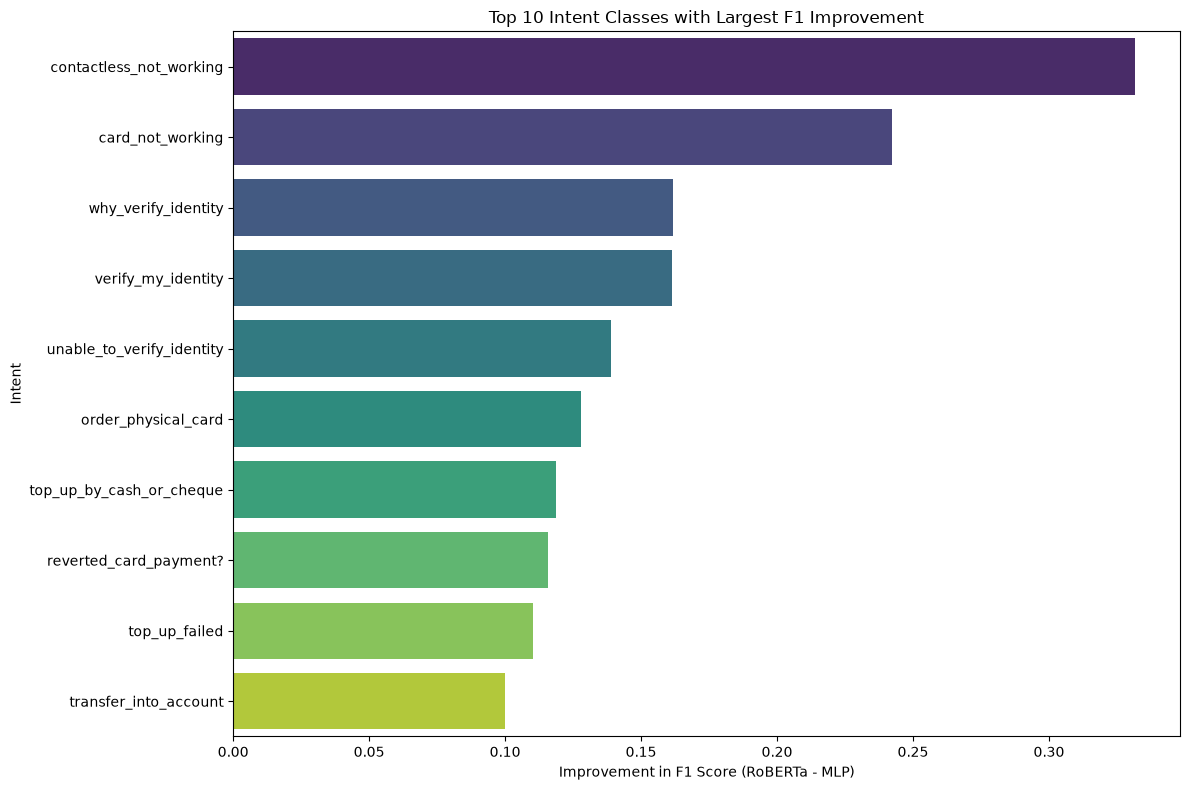

,MLP,RoBERTa,Difference
Precision,0.885436,0.934264,0.048828
Recall,0.878571,0.932143,0.053571
F1 Score,0.878533,0.932044,0.053512


,MLP,RoBERTa,Difference
Precision,0.885436,0.934264,0.048828
Recall,0.878571,0.932143,0.053571
F1 Score,0.878533,0.932044,0.053512
Accuracy,0.878571,0.932143,0.053571
Macro F1,0.878533,0.932044,0.053512


,Training/search/selection seconds,Test prediction seconds (includes batching),"Peak allocated GPU GiB (process, training phase)",Total parameters,Trainable parameters
MLP,4.062766,0.113994,0.614835,6295629,6295629
RoBERTa,479.055525,2.733809,1.439285,125944474,1239629


Paired bootstrap accuracy difference, 95% CI (percentage points): [4.25 6.43]
RoBERTa-only correct: 227; MLP-only correct: 62
MLP: classes with no predictions: []
RoBERTa: classes with no predictions: []
This is a validation-selected, single-seed, budget-constrained comparison, not proof of global optimization.


In [8]:
# classification report already imported

# -------------------------------------------
# MLP Classification Report
# -------------------------------------------

mlp_report = classification_report(
    all_targets,
    all_predictions,
    target_names=label_encoder.classes_.tolist(),
    labels=list(range(num_classes)),
    output_dict=True,
    zero_division=0
)

# -------------------------------------------
# RoBERTa Classification Report
# -------------------------------------------

# Trainer's predict annotation accepts torch Dataset, while its runtime supports HF Dataset too.
# Use a typed torch wrapper instead of suppressing that library annotation mismatch.
from torch.utils.data import Dataset as TorchDataset

class TokenizedRows(TorchDataset):
    def __init__(self, rows: Dataset) -> None:
        self.rows = rows

    def __len__(self) -> int:
        return len(self.rows)

    def __getitem__(self, index: int) -> dict[str, object]:
        return dict(self.rows[index])

torch.cuda.synchronize()
roberta_prediction_started = perf_counter()
roberta_predictions = trainer.predict(TokenizedRows(test_dataset_roberta))
torch.cuda.synchronize()
roberta_prediction_seconds = perf_counter() - roberta_prediction_started

roberta_logits = roberta_predictions.predictions
if isinstance(roberta_logits, tuple):
    roberta_logits = roberta_logits[0]
roberta_pred_labels = np.asarray(roberta_logits).argmax(axis=1)

roberta_true_labels = roberta_predictions.label_ids
if roberta_true_labels is None or isinstance(roberta_true_labels, tuple):
    raise ValueError("Expected one array of test labels.")
np.testing.assert_array_equal(roberta_true_labels, y_test)

roberta_report = classification_report(
    roberta_true_labels,
    roberta_pred_labels,
    target_names=label_encoder.classes_.tolist(),
    labels=list(range(num_classes)),
    output_dict=True,
    zero_division=0
)

if not isinstance(mlp_report, dict) or not isinstance(roberta_report, dict):
    raise TypeError("Expected dictionary classification reports.")
print("Classification reports generated successfully.")

intent_classes = list(label_encoder.classes_)

mlp_metrics = pd.DataFrame.from_dict(
    {
        intent: mlp_report[intent]
        for intent in intent_classes
    },
    orient="index"
)

roberta_metrics = pd.DataFrame.from_dict(
    {
        intent: roberta_report[intent]
        for intent in intent_classes
    },
    orient="index"
)

mlp_metrics.index.name = "intent"
roberta_metrics.index.name = "intent"

comparison_df = pd.DataFrame(index=pd.Index(intent_classes, name="intent"))

comparison_df["MLP Precision"] = mlp_metrics["precision"]
comparison_df["RoBERTa Precision"] = roberta_metrics["precision"]

comparison_df["MLP Recall"] = mlp_metrics["recall"]
comparison_df["RoBERTa Recall"] = roberta_metrics["recall"]

comparison_df["MLP F1"] = mlp_metrics["f1-score"]
comparison_df["RoBERTa F1"] = roberta_metrics["f1-score"]

# -------------------------------------------
# Performance Improvements
# -------------------------------------------

comparison_df["Precision Difference"] = (
    comparison_df["RoBERTa Precision"]
    - comparison_df["MLP Precision"]
)

comparison_df["Recall Difference"] = (
    comparison_df["RoBERTa Recall"]
    - comparison_df["MLP Recall"]
)

comparison_df["F1 Difference"] = (
    comparison_df["RoBERTa F1"]
    - comparison_df["MLP F1"]
)

display(comparison_df.head())

top_10_improved = (
    comparison_df
    .sort_values(
        by="F1 Difference",
        ascending=False
    )
    .head(10)
)

print("Top 10 Intent Improvements")
display(top_10_improved)

bottom_10_improved = (
    comparison_df
    .sort_values(
        by="F1 Difference",
        ascending=True
    )
    .head(10)
)

print("Bottom 10 Intent Improvements")
display(bottom_10_improved)

plt.figure(figsize=(12, 8))

sns.barplot(
    data=top_10_improved.reset_index(),
    x="F1 Difference",
    y="intent",
    hue="intent",
    palette="viridis",
    legend=False
)

plt.title(
    "Top 10 Intent Classes with Largest F1 Improvement"
)

plt.xlabel(
    "Improvement in F1 Score (RoBERTa - MLP)"
)

plt.ylabel("Intent")

plt.tight_layout()
plt.show()

summary_comparison = pd.DataFrame(
    {
        "MLP": [
            mlp_report["weighted avg"]["precision"],
            mlp_report["weighted avg"]["recall"],
            mlp_report["weighted avg"]["f1-score"]
        ],
        "RoBERTa": [
            roberta_report["weighted avg"]["precision"],
            roberta_report["weighted avg"]["recall"],
            roberta_report["weighted avg"]["f1-score"]
        ]
    },
    index=[
        "Precision",
        "Recall",
        "F1 Score"
    ]
)

summary_comparison["Difference"] = (
    summary_comparison["RoBERTa"]
    - summary_comparison["MLP"]
)

display(summary_comparison)

summary_comparison.loc["Accuracy", ["MLP", "RoBERTa"]] = [
    accuracy_score(y_test, all_predictions), accuracy_score(y_test, roberta_pred_labels)
]
summary_comparison.loc["Macro F1", ["MLP", "RoBERTa"]] = [
    float(f1_score(y_test, all_predictions, average="macro", zero_division=0)),
    float(f1_score(y_test, roberta_pred_labels, average="macro", zero_division=0))
]
summary_comparison["Difference"] = summary_comparison["RoBERTa"] - summary_comparison["MLP"]
display(summary_comparison)
display(pd.DataFrame({
    "Training/search/selection seconds": [mlp_training_seconds, roberta_training_seconds],
    "Test prediction seconds (includes batching)": [mlp_prediction_seconds, roberta_prediction_seconds],
    "Peak allocated GPU GiB (process, training phase)": [mlp_peak_gib, roberta_peak_gib],
    "Total parameters": [sum(p.numel() for p in mlp_model.parameters()), sum(p.numel() for p in model.parameters())],
    "Trainable parameters": [
        sum(p.numel() for p in mlp_model.parameters() if p.requires_grad),
        sum(p.numel() for p in model.parameters() if p.requires_grad)
    ]
}, index=["MLP", "RoBERTa"]))

mlp_correct = np.asarray(all_predictions) == y_test
roberta_correct = roberta_pred_labels == y_test
rng = np.random.default_rng(SEED)
paired_deltas = np.empty(2000)
for iteration in range(len(paired_deltas)):
    indices = rng.integers(0, len(y_test), size=len(y_test))
    paired_deltas[iteration] = (
        roberta_correct[indices].mean() - mlp_correct[indices].mean()
    )
print("Paired bootstrap accuracy difference, 95% CI (percentage points):",
      np.round(100 * np.percentile(paired_deltas, [2.5, 97.5]), 2))
print(f"RoBERTa-only correct: {np.sum(roberta_correct & ~mlp_correct)}; "
      f"MLP-only correct: {np.sum(mlp_correct & ~roberta_correct)}")
for name, predicted in (("MLP", all_predictions), ("RoBERTa", roberta_pred_labels)):
    missing = sorted(set(range(num_classes)) - set(predicted))
    print(f"{name}: classes with no predictions: {label_encoder.inverse_transform(missing).tolist() if missing else []}")
print("This is a validation-selected, single-seed, budget-constrained comparison, not proof of global optimization.")
summary_comparison.to_csv(OUTPUT / "summary_comparison.csv")
comparison_df.to_csv(OUTPUT / "per_intent_comparison.csv")


## Inference on realistic banking queries

These are synthetic, realistic customer questions, not private customer records or
additional test observations. Both models use the preprocessing fitted above.
Softmax scores are **uncalibrated**, not probabilities of correctness. This closed-set
demo always picks one of 77 intents; it does not detect out-of-domain requests,
guarantee removal of all PII, or authorize banking actions.

In [9]:
banking_queries = [
    "My card still hasn't arrived after two weeks. Can you check the delivery?",
    "I lost my wallet and need to block my bank card immediately.",
    "The cash machine kept my card. How do I get it back?",
    "I see the same card purchase charged twice on my statement.",
    "I forgot the passcode for the app. How can I sign in?",
    "I sent a bank transfer yesterday but the recipient hasn't received it.",
    "How do I change the PIN on my card?",
    "My contactless payments stopped working, but the chip still works.",
]

def predict_banking_queries(queries: list[str]) -> pd.DataFrame:
    if not queries or any(not query.strip() for query in queries):
        raise ValueError("Provide at least one non-empty banking query.")
    # Training-serving parity: both classifiers receive the same protected queries.
    # Return protected queries only; never echo raw customer text or detector spans.
    protected = protector.protect(queries)
    safe_queries = protected.texts
    features = csr_matrix(tfidf_vectorizer.transform(safe_queries), dtype=np.float32)
    mlp_model.eval()
    model.eval()
    encoded = tokenizer(
        safe_queries, padding=True, truncation=True, max_length=64, return_tensors="pt"
    ).to(device)
    with torch.inference_mode():
        mlp_scores = mlp_model(torch.from_numpy(features.toarray()).to(device)).softmax(dim=-1)
        transformer_output = model(**encoded)
        transformer_logits = transformer_output.logits
        roberta_scores = transformer_logits.float().softmax(dim=-1)
    mlp_ids = mlp_scores.argmax(dim=-1).cpu().numpy()
    roberta_ids = roberta_scores.argmax(dim=-1).cpu().numpy()
    return pd.DataFrame({
        "Protected query": safe_queries,
        "MLP intent": label_encoder.inverse_transform(mlp_ids),
        "MLP score (uncalibrated)": mlp_scores.max(dim=-1).values.cpu().numpy(),
        "RoBERTa intent": label_encoder.inverse_transform(roberta_ids),
        "RoBERTa score (uncalibrated)": roberta_scores.max(dim=-1).values.cpu().numpy(),
        "Agree": mlp_ids == roberta_ids,
    })

display(predict_banking_queries(banking_queries))

# Invented PII demonstrates the inference boundary; do not paste real identities
# into notebook source, because source itself is persisted independently of outputs.
synthetic_sensitive_queries = [
    "My name is Jane Doe. My card 4111 1111 1111 1111 was declined. Email jane@example.com.",
    "Please send my replacement card to 42 Maple Street, London SW1A 1AA.",
]
display(predict_banking_queries(synthetic_sensitive_queries))

# Persist reproducibility evidence, not raw examples, identities, offsets or mappings.
privacy_manifest = {
    "policy_version": POLICY_VERSION,
    "ner_model": NER_MODEL, "ner_revision": NER_REVISION,
    "intent_base_model": model_name, "intent_base_revision": ROBERTA_REVISION,
    "language_and_scope": "English; US/UK structured identifiers plus PER/LOC NER",
    "protection_seconds": privacy_seconds, "seed": SEED,
    "train_aggregate_counts": train_pii_audit, "test_aggregate_counts": test_pii_audit,
    "collision_counts": collision_audit,
    "split_sizes": {"train": len(fit_df), "validation": len(validation_df), "test": len(test_df)},
    "model_selection": "validation macro F1 only; identical protected splits",
    "versions": {package: version(package) for package in (
        "torch", "transformers", "peft", "scikit-learn", "wordcloud"
    )},
    "release_status": "educational public-data run; not approved for live customer data",
}
(OUTPUT / "privacy_manifest.json").write_text(
    json.dumps(privacy_manifest, indent=2), encoding="utf-8"
)
print("Aggregate-only privacy manifest saved; raw customer text and reversible mappings are not exported.")
torch.cuda.synchronize()
total_seconds = perf_counter() - run_started
print(f"Full protected run (including PII checks, plots, model loading, evaluation, saving and inference): {total_seconds:.1f}s ({total_seconds / 60:.2f} min)")
print(f"Approximate ten-minute target met: {total_seconds <= 600}")


,Protected query,MLP intent,MLP score (uncalibrated),RoBERTa intent,RoBERTa score (uncalibrated),Agree
0,My card still hasn't arrived after two weeks. ...,card_arrival,0.996910,card_arrival,0.998627,True
1,I lost my wallet and need to block my bank car...,transfer_into_account,0.560290,lost_or_stolen_card,0.890324,False
2,The cash machine kept my card. How do I get it...,card_swallowed,0.918980,card_swallowed,0.997656,True
3,I see the same card purchase charged twice on ...,transaction_charged_twice,0.999365,transaction_charged_twice,0.999993,True
4,I forgot the passcode for the app. How can I s...,passcode_forgotten,0.970894,passcode_forgotten,0.999907,True
5,I sent a bank transfer yesterday but the recip...,transfer_not_received_by_recipient,0.990801,transfer_not_received_by_recipient,0.999423,True
6,How do I change the PIN on my card?,change_pin,0.967120,change_pin,0.999195,True
7,"My contactless payments stopped working, but t...",contactless_not_working,0.765469,contactless_not_working,0.996647,True


,Protected query,MLP intent,MLP score (uncalibrated),RoBERTa intent,RoBERTa score (uncalibrated),Agree
0,My name is <PERSON>. My card <CARD> was declin...,unable_to_verify_identity,0.506801,declined_card_payment,0.905157,False
1,"Please send my replacement card to <ADDRESS>, ...",card_delivery_estimate,0.317419,card_about_to_expire,0.982317,False


Aggregate-only privacy manifest saved; raw customer text and reversible mappings are not exported.
Full protected run (including PII checks, plots, model loading, evaluation, saving and inference): 530.1s (8.83 min)
Approximate ten-minute target met: True
